# Solar and Satellite Join
So, this is just to create a dataset that we call on in Dashboard_Load.

We load in the entire OS free map for the TQ tile that encompasses London, seems like we can't pre-bound it so the file 'osopentoid_202611_tq.gpkg' is pretty big. 

We then bound it to a box containing Southwark, if you wanted to extend this map to all of London you'd just change the bounding box here.

We then read in the London Solar Opportunity Map (this is old, from 2019/20, so would be good to get a more up to date one, maybe using Solar Wizard, this would also give us kW peak - need to check licenses). 

We inner join by the 'TOID', which is an identifier for each unique building. Joining LSOM to OS gives us the coordinates of the buildings so that we can then plot them on a satellite map.

The dataset is saved to "Southwark/southwark_joined_solar.gpkg"

In [2]:
import pandas as pd
import geopandas as gpd


c:\Users\odhra\OneDrive\Documents\Work\CES\solar project\London-Solar-Map\.solar_venv\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'osopentoid_202611_tq.gpkg': 'os_mastermap_topography_layer' (default), 'os_mastermap_sites_layer', 'os_mastermap_highways_network'. Specify layer parameter to avoid this warning.
  result = read_func(


Loaded 3,026,538 features


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

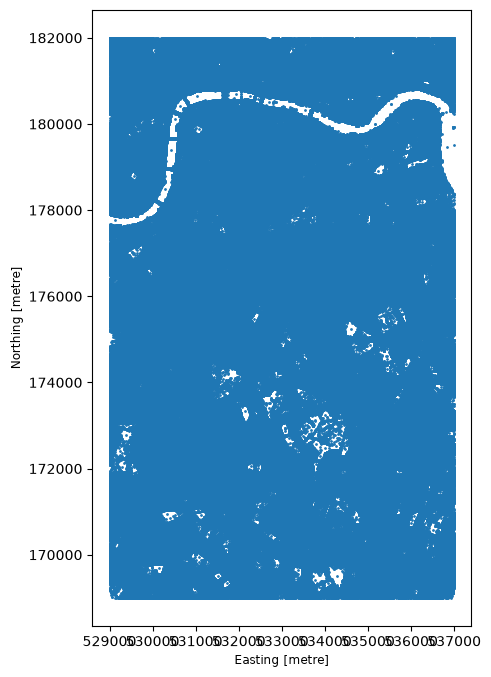

In [ ]:
# Bounding around southwark

path = "osopentoid_202611_gpkg_tq\osopentoid_202611_tq.gpkg"

# British National Grid: min easting, min northing, max easting, max northing
bbox = (529000, 169000, 537000, 182000)

southwark = gpd.read_file(path, bbox=bbox)

print(f"Loaded {len(southwark):,} features")
southwark.plot(figsize=(8, 8), markersize=1)

lsom = pd.read_csv(
    "LSOM/LSOM_by_TOID.csv",
    dtype={"fid_topo": "string"}
)

southwark["TOID"] = southwark["TOID"].astype("string").str.strip()
lsom["fid_topo"] = lsom["fid_topo"].str.strip()

sites = southwark.merge(
    lsom,
    left_on="TOID",
    right_on="fid_topo",
    how="inner"
)

print(f"Matched rows: {len(sites):,}")

sites.to_file("Southwark/southwark_joined_solar.gpkg", driver="GPKG")

We've joined the OS and Solar maps. Now to start filtering by roof size.

In [3]:
southwark = gpd.read_file("Southwark/southwark_joined_solar.gpkg")

## Joining Land Registry Info

In [4]:
southwark.head(5)

,TOID,VERSION_NUMBER,VERSION_DATE,EASTING,NORTHING,fid_topo,avg_potential_m2_viable,area3d_in_potential,sum_total_potential,avg_tilt,lidar_date,geometry
0,osgb1000042342965,6,2006-02-19,534574.0625,169996.640625,osgb1000042342965,881.708435,40.1060,35361.798505,18.468874,2015.0,POINT (534574.042 169996.644)
1,osgb1000006145753,5,2006-02-19,534576.6875,170001.687500,osgb1000006145753,884.206440,41.8536,37007.222642,19.586624,2015.0,POINT (534576.694 170001.682)
2,osgb1000042343044,3,2006-02-19,534565.0625,169940.437500,osgb1000042343044,846.916793,0.2825,239.253994,27.800000,2015.0,POINT (534565.037 169940.443)
3,osgb1000042343038,4,2017-08-08,534574.5625,169943.234375,osgb1000042343038,904.289995,46.1740,41754.686250,34.062329,2015.0,POINT (534574.541 169943.228)
4,osgb1000042343039,3,2006-02-19,534572.2500,169947.312500,osgb1000042343039,849.852795,43.6096,37061.740447,36.832090,2015.0,POINT (534572.259 169947.316)


In [ ]:
land_reg = gpd.read_file('LandRegistry/Land_Registry_Cadastral_Parcels.gml')

In [8]:
land_reg.head(5)

,gml_id,INSPIREID,LABEL,NATIONALCADASTRALREFERENCE,VALIDFROM,BEGINLIFESPANVERSION,geometry
0,PREDEFINED.fid--39c8aa1d_1a1952f2ec1_-4428,38157199,38157199,38157199,2009-11-18 09:54:09.846+00:00,2009-11-18 09:54:09.846+00:00,"POLYGON ((536072.085 174502.317, 536106.9 1745..."
1,PREDEFINED.fid--39c8aa1d_1a1952f2ec1_-4427,38141889,38141889,38141889,2007-12-17 09:37:13.090+00:00,2007-12-17 09:37:13.090+00:00,"POLYGON ((536062.125 174504.771, 536064.057 17..."
2,PREDEFINED.fid--39c8aa1d_1a1952f2ec1_-4426,38141888,38141888,38141888,2007-12-12 12:14:13.208+00:00,2007-12-12 12:14:13.208+00:00,"POLYGON ((536062.125 174504.771, 536064.057 17..."
3,PREDEFINED.fid--39c8aa1d_1a1952f2ec1_-4425,38158417,38158417,38158417,2007-12-14 14:21:51.244+00:00,2007-12-14 14:21:51.244+00:00,"POLYGON ((536068.472 174610.349, 536071.24 174..."
4,PREDEFINED.fid--39c8aa1d_1a1952f2ec1_-4424,38161408,38161408,38161408,2002-07-17 23:00:00.000+00:00,2002-07-17 23:00:00.000+00:00,"POLYGON ((536084.25 174598.05, 536086.6 174604..."
